In [1]:
import sionna.rt as rt
import numpy as np

scene = rt.load_scene(
    rt.scene.simple_street_canyon,
    merge_shapes=False
)

jitc_llvm_init(): LLVM API initialization failed ..


In [2]:
tx = rt.Transmitter(
    name = "tx",
    position=[0, 0, 25],
    display_radius=2
)

scene.add(tx)

In [3]:
print(scene.transmitters)
print(scene.get("tx").position)

{'tx': <sionna.rt.radio_devices.transmitter.Transmitter object at 0x0000021BD5301FD0>}
[[0, 0, 25]]


In [4]:
rx = rt.Receiver(
    name = "rx",
    position = [0, 0, 1.5],
    display_radius=1
)

scene.add(rx)

In [5]:
print(scene.receivers)
print(scene.get("rx").position)

{'rx': <sionna.rt.radio_devices.receiver.Receiver object at 0x0000021BD53023C0>}
[[0, 0, 1.5]]


In [6]:
scene.tx_array = rt.PlanarArray(
    num_rows=1,
    num_cols=1,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="iso",
    polarization="V"
)

In [7]:
scene.rx_array = rt.PlanarArray(
    num_rows=1,
    num_cols=1,
    vertical_spacing=0.5,
    horizontal_spacing=0.5,
    pattern="iso",
    polarization="V"
)

In [8]:
scene.frequency = 3.5e9

solver = rt.PathSolver()

paths = solver(
    scene=scene,
    max_depth=0
)

print(paths.valid)

paths_one_bounce = solver(
    scene=scene,
    max_depth=1,
    specular_reflection=True
)

print(paths_one_bounce.valid)

[[[True]]]
[[[True, True, True, True]]]


In [9]:
scene.preview(paths=paths_one_bounce)

In [10]:
l = paths_one_bounce.tau

lengths = np.array([item * 299_792_458 for item in l])
largest = lengths.max()
shortest_path = lengths[0][0][0]

print(lengths)
print(lengths.shape)
print("Longer than straight:", largest - shortest_path)

[[[23.499998 29.137743 30.310217 26.561586]]]
(1, 1, 4)
Longer than straight: 6.810219


In [11]:
a, tau = paths_one_bounce.cir(
    normalize_delays=False,
    out_type="numpy"
)

coefficients = a.reshape(-1)

amplitude_gains = np.abs(coefficients)
power_gains = np.abs(coefficients) ** 2

print("Комплексні коефіцієнти:", coefficients)
print("Множники амплітуди:", amplitude_gains)
print("Множники потужності:", power_gains)
print("Найбільший множник потужності:", power_gains.max())

Комплексні коефіцієнти: [ 1.7986786e-04+2.2754636e-04j  1.6990614e-06+2.4923136e-06j
 -2.5861904e-05-2.1318242e-06j -8.8909466e-05+6.1956940e-05j]
Множники амплітуди: [2.9005139e-04 3.0163615e-06 2.5949621e-05 1.0836768e-04]
Множники потужності: [8.4129809e-08 9.0984364e-12 6.7338285e-10 1.1743555e-08]
Найбільший множник потужності: 8.412981e-08


In [12]:
transmit_power_w = 0.5

received_power_w = transmit_power_w * power_gains
power_dbm = 10 * np.log10(received_power_w / 1e-3)

max_power = power_dbm.max()
min_power = power_dbm.min()

print(power_dbm)
print(max_power)
print(min_power)
print(max_power - min_power)

[-43.7608  -83.42063 -64.72768 -52.3123 ]
-43.7608
-83.42063
39.659832


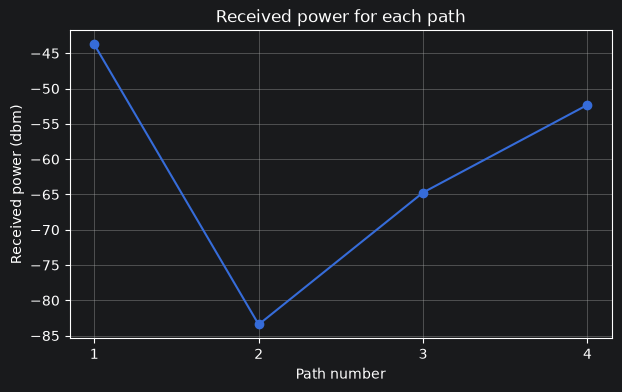

In [13]:
import matplotlib.pyplot as plt

path_numbers = np.arange(1, len(power_dbm) + 1)

plt.figure(figsize=(7,4))
plt.plot(path_numbers, power_dbm, marker = "o")

plt.xlabel("Path number")
plt.ylabel("Received power (dbm)")
plt.title("Received power for each path")

plt.xticks(path_numbers)
plt.grid(True)
plt.show()